# PINN — Flujo de Couette **no estacionario** (3 condiciones)

Navier Stokes a resolver:

$$\frac{\partial u}{\partial t} = \nu\,\frac{\partial^2 u}{\partial y^2}, \qquad y\in[0,1],\; t\in[0,T]$$

| Condición | Significado |
|---|---|
| $u(y,0) = 0$ | Fluido inicialmente en reposo (CI) |
| $u(0,t) = 0$ | Placa inferior fija |
| $u(1,t) = 1 - e^{-t/\tau}$ | Placa superior que **acelera suavemente** desde el reposo hasta $u=1$ |


In [2]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import matplotlib.cm as cm

from neurodiffeq import diff
from neurodiffeq.solvers import Solver2D
from neurodiffeq.conditions import IBVP1D
from neurodiffeq.networks import FCNN
from neurodiffeq.generators import Generator2D

C:\Users\carlo\anaconda3\Lib\site-packages\torch\__init__.py:1323: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\tensor\python_tensor.cpp:436.)
  _C._set_default_tensor_type(t)


## Parámetros físicos


In [4]:
nu       = 0.1   
T_MAX    = 5
TAU_RAMP = 1   

## Definición de la PDE

$$\frac{\partial u}{\partial t} - \nu\,\frac{\partial^2 u}{\partial y^2} = 0$$



In [6]:
def pde(u, y, t):
    """Residuo de la ecuación de difusión: du/dt - nu * d²u/dy² = 0"""
    return diff(u, t) - nu * diff(u, y, order=2)

## Condiciones inicial y de contorno (solo las físicas)


| Parámetro de `IBVP1D` | Condición física |
|---|---|
| `t_min=0`, `t_min_val=lambda y: 0`  | $u(y,0)=0$ — fluido en reposo |
| `x_min=0`, `x_min_val=lambda t: 0`  | $u(0,t)=0$ — placa inferior fija |
| `x_max=1`, `x_max_val=lambda t: 1 - e^{-t/\tau}`  | $u(1,t) = 1-e^{-t/\tau}$ — placa superior con arranque suave (evita la discontinuidad de esquina en $(y,t)=(1,0)$) |



In [8]:
condition = IBVP1D(                      
    x_min=0,     x_min_val=lambda t: torch.zeros_like(t),                        
    x_max=1,     x_max_val=lambda t: 1 - torch.exp(-t / TAU_RAMP),      
    t_min=0,     t_min_val=lambda y: torch.zeros_like(y)
)


In [9]:
net = FCNN(
    n_input_units=2,
    n_output_units=1,
    hidden_units=(16,16),   # más capacidad: la esquina (y=1, t=0) es discontinua
    actv=nn.SiLU,
)

print(net)

FCNN(
  (NN): Sequential(
    (0): Linear(in_features=2, out_features=16, bias=True)
    (1): SiLU()
    (2): Linear(in_features=16, out_features=16, bias=True)
    (3): SiLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)


## Solver de la red



In [11]:
# Generadores con más puntos para resolver mejor la capa límite cerca de t=0
train_gen = Generator2D(grid=(64, 64), xy_min=(0.0, 0.0), xy_max=(1.0, T_MAX), method='equally-spaced-noisy')
valid_gen = Generator2D(grid=(32, 32), xy_min=(0.0, 0.0), xy_max=(1.0, T_MAX), method='equally-spaced')

solver = Solver2D(
    pde_system=pde,
    conditions=[condition],
    xy_min=(0.0, 0.0),
    xy_max=(1.0, T_MAX),
    nets=[net],
    train_generator=train_gen,
    valid_generator=valid_gen,
)


# Bajar el learning rate directamente sobre el optimizador interno
for param_group in solver.optimizer.param_groups:
    param_group['lr'] = 1e-4

solver.fit(max_epochs=20000)
solution = solver.get_solution(best=True)
print("Entrenamiento completado.")


Training Progress:   0%|          | 0/20000 [00:00<?, ?it/s]

Entrenamiento completado.


In [12]:
print(solution)

In [13]:
y_check = np.linspace(0, 1, 100)             
t_check = np.array([0,0.01,0.05,0.1,0.15,0.25, 0.5, 1.0, 2.0, T_MAX])

u_y1 = solution(np.ones_like(t_check),  t_check, to_numpy=True).flatten()

print(u_y1)

[0.         0.00995017 0.04877058 0.09516258 0.13929202 0.22119922
 0.39346934 0.63212056 0.86466472 0.99326205]


## Curvas de pérdida

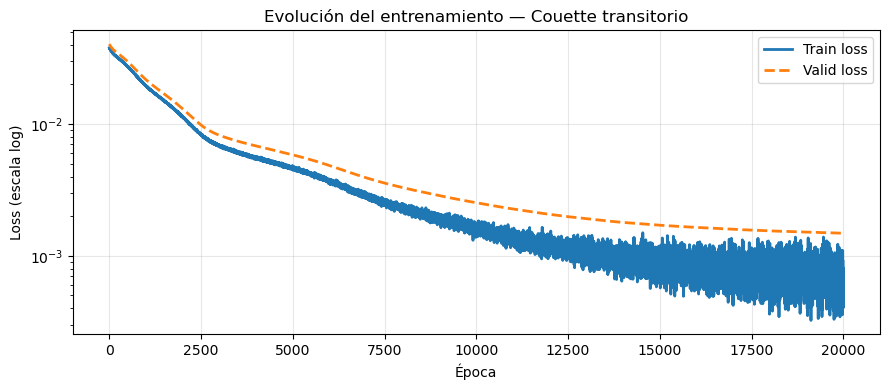

In [15]:
loss = solver.metrics_history

plt.figure(figsize=(9, 4))
plt.semilogy(loss['train_loss'], label='Train loss', linewidth=2)
plt.semilogy(loss['valid_loss'], label='Valid loss', linewidth=2, linestyle='--')
plt.xlabel('Época'); plt.ylabel('Loss (escala log)')
plt.title('Evolución del entrenamiento — Couette transitorio')
plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

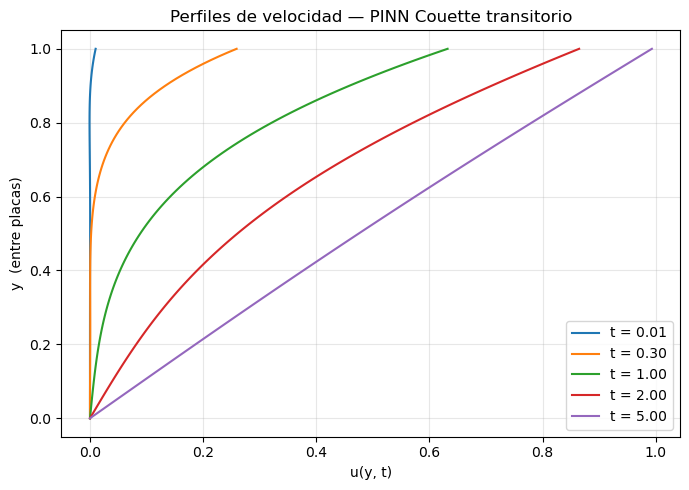

In [16]:
y_test = np.linspace(0, 1, 100)

plt.figure(figsize=(7, 5))
for t_val in [0.01,0.3, 1.0, 2.0, T_MAX]:
    t_arr  = np.full_like(y_test, t_val)
    u_pred = solution(y_test, t_arr, to_numpy=True).flatten()
    plt.plot(u_pred, y_test, label=f't = {t_val:.2f}')

plt.xlabel('u(y, t)')
plt.ylabel('y  (entre placas)')
plt.title('Perfiles de velocidad — PINN Couette transitorio')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
print(u_pred)

[0.         0.00938687 0.01877274 0.02815835 0.03754448 0.04693185
 0.0563212  0.06571325 0.07510871 0.08450827 0.09391261 0.10332239
 0.11273828 0.12216092 0.13159092 0.1410289  0.15047546 0.15993117
 0.16939661 0.17887233 0.18835885 0.1978567  0.20736639 0.2168884
 0.2264232  0.23597125 0.24553299 0.25510884 0.26469922 0.27430451
 0.28392509 0.29356133 0.30321357 0.31288215 0.32256738 0.33226957
 0.341989   0.35172597 0.36148071 0.3712535  0.38104456 0.39085413
 0.40068241 0.4105296  0.42039591 0.43028151 0.44018657 0.45011125
 0.46005571 0.47002007 0.48000448 0.49000906 0.50003392 0.51007917
 0.5201449  0.53023121 0.54033816 0.55046584 0.5606143  0.5707836
 0.58097377 0.59118486 0.60141688 0.61166986 0.62194378 0.63223865
 0.64255443 0.65289109 0.66324859 0.67362685 0.68402579 0.69444532
 0.70488531 0.71534563 0.72582612 0.73632659 0.74684684 0.75738664
 0.76794571 0.77852378 0.78912051 0.79973554 0.81036849 0.82101892
 0.83168635 0.84237027 0.85307012 0.86378528 0.8745151  0.885258

In [18]:

def couette_fd_profile(t_target, nu, tau, y_max=1.0, n_y=201):
    if t_target <= 0:
        return np.linspace(0, y_max, n_y), np.zeros(n_y)

    y  = np.linspace(0, y_max, n_y)
    dy = y[1] - y[0]
    dt = 0.4 * dy**2 / nu                       # estabilidad FTCS: r = nu*dt/dy^2 <= 0.5
    n_steps = max(1, int(np.ceil(t_target / dt)))
    dt = t_target / n_steps
    r  = nu * dt / dy**2

    u = np.zeros(n_y)
    for step in range(1, n_steps + 1):
        t = step * dt
        u_new = u.copy()
        u_new[1:-1] = u[1:-1] + r * (u[2:] - 2.0 * u[1:-1] + u[:-2])
        u_new[0]  = 0.0
        u_new[-1] = 1.0 - np.exp(-t / tau)
        u = u_new
    return y, u

print("Errores L_inf vs. solución de referencia (diferencias finitas):")
for t_val in [0.1, 0.5, 1.0, 2.0, T_MAX]:
    t_arr = np.full_like(y_test, t_val)
    u_pred       = solution(y_test, t_arr, to_numpy=True).flatten()
    y_ref, u_ref_grid = couette_fd_profile(t_val, nu, TAU_RAMP)
    u_ref        = np.interp(y_test, y_ref, u_ref_grid)
    print(f"  t = {t_val:5.2f}   max|u_pred - u_ref| = {np.max(np.abs(u_pred - u_ref)):.3e}")

# Convergencia asintótica al estacionario u(y) = y (sigue siendo válida: para t grande,
# 1 - exp(-t/tau) -> 1, así que el problema converge al mismo perfil lineal de Couette)
t_arr = np.full_like(y_test, T_MAX)
u_pred = solution(y_test, t_arr, to_numpy=True).flatten()
print(f"\nConvergencia asintótica:  max|u(y, T_MAX) - y| = {np.max(np.abs(u_pred - y_test)):.3e}")


Errores L_inf vs. solución de referencia (diferencias finitas):
  t =  0.10   max|u_pred - u_ref| = 2.413e-03
  t =  0.50   max|u_pred - u_ref| = 6.195e-04
  t =  1.00   max|u_pred - u_ref| = 6.118e-04
  t =  2.00   max|u_pred - u_ref| = 3.624e-04
  t =  5.00   max|u_pred - u_ref| = 4.220e-04

Convergencia asintótica:  max|u(y, T_MAX) - y| = 2.532e-02


## Mapa de calor 

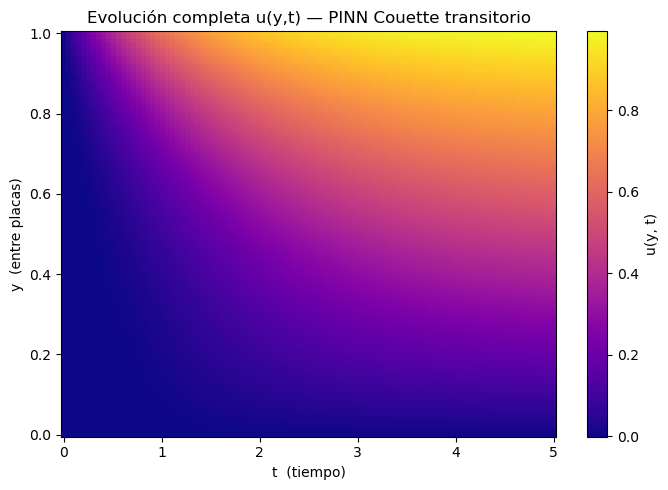

In [20]:
N_y, N_t = 100, 100
y_grid = np.linspace(0, 1, N_y)
t_grid = np.linspace(0, T_MAX, N_t)
YY, TT = np.meshgrid(y_grid, t_grid)

u_pred = solution(YY.flatten(), TT.flatten(), to_numpy=True).reshape(N_t, N_y)

plt.figure(figsize=(7, 5))
plt.pcolormesh(t_grid, y_grid, u_pred.T, cmap='plasma', shading='auto')
plt.colorbar(label='u(y, t)')
plt.xlabel('t  (tiempo)')
plt.ylabel('y  (entre placas)')
plt.title('Evolución completa u(y,t) — PINN Couette transitorio')
plt.tight_layout()
plt.show()

### Probamos capas de la Red 